# **Q-Billings**

### O Projeto Q-Billings é um sistema inteligente de monitoramento ambiental para a Represa Billings, em São Bernardo do Campo, que automatiza todo o processo de fiscalização em três etapas: utiliza visão computacional (U-Net) em imagens de satélite Sentinel-2 para detetar autonomamente focos de desmatamento, converte esses pontos em coordenadas geográficas precisas (GIS / UTM SIRGAS 2000) e aplica otimização combinatória quântica (QUBO / QAOA) para calcular a rota de patrulhamento mais curta e eficiente para a Guarda Ambiental ($N0 \rightarrow N2 \rightarrow N1 \rightarrow N0$), economizando tempo e combustível.




## Fase 1 - Sensoriamento Remoto & Segmentação com Deep Learning (U-Net)

Nesta primeira etapa, o pipeline automatiza a identificação e o isolamento de áreas degradadas na APA Billings por meio de técnicas avançadas de visão computacional:

* **Entrada de Dados Multiespectrais:** Carregamento e pré-processamento das bandas espectrais de imagens do satélite Sentinel-2 referentes à região da Represa Billings em São Bernardo do Campo.
* **Predição via Arquitetura U-Net:** Aplicação de uma rede neural convolucional profunda (U-Net) treinada para segmentação semântica. O modelo analisa as assinaturas espectrais do terreno e classifica pixels de supressão vegetal, desmatamento e ocupações em Áreas de Preservação Permanente (APP).
* **Geração da Máscara Binária:** Extração de uma matriz binária (raster de saída) onde os pixels ativos identificam autonomamente a localização dos focos prioritários de fiscalização ambiental.

## 1. Instalação e Importação das Bibliotecas Nativas e Geográficas

Nesta primeira etapa, realizamos a instalação e importação do conjunto de ferramentas necessárias para o pipeline de Sensoriamento Remoto e Visão Computacional:
* **`rasterio`**: Para manipulação, leitura e gravação de matrizes de dados geográficos no formato GeoTIFF.
* **`segmentation_models_pytorch` (SMP)**: Para fornecimento de arquiteturas pré-treinadas de segmentação semântica (U-Net).
* **`torch` & `torchvision`**: Para criação do dataset, tensores e execução do modelo em GPU.
* **`matplotlib` & `numpy`**: Para processamento matricial e visualização dos resultados geográficos.

In [ ]:

# 1. Instalação e Importação de Dependências

!pip install -q rasterio segmentation-models-pytorch torch torchvision matplotlib numpy

import os
import matplotlib.pyplot as plt
import numpy as np
import rasterio
import segmentation_models_pytorch as smp
import torch
import torch.nn as nn
from rasterio.transform import from_origin
from torch.utils.data import DataLoader, Dataset

# Configuração de dispositivo de processamento (GPU se disponível)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo em execução: {device}')

Dispositivo em execução: cpu


## 2. Ingestão e Preparação do Dado Raster GeoTIFF (Sentinel-2 / CBERS-4A)

Para simular o ambiente de sensoriamento remoto de alta resolução sobre a região do pós-balsa da Represa Billings em São Bernardo do Campo:
1. Criação de um raster multiespectral sintético com 4 bandas (Vermelho, Verde, Azul e Infravermelho Próximo - NIR).
2. Adicionei padrões simulados de perturbação e supressão de vegetação nativa na banda NIR.
3. Exportei a matriz no formato geográfico **GeoTIFF** com projeção cartográfica **SIRGAS 2000 / UTM zone 23S (EPSG:31983)**, condizente com o município de São Bernardo do Campo.

In [ ]:
# ------------------------------------------------------------------------------
# 2. Ingestão e Preparação do Dado Raster GeoTIFF (Sentinel-2 / CBERS-4A)
# ------------------------------------------------------------------------------
raster_path = 'sbc_billings_sentinel2.tif'
width, height = 1024, 1024
num_bands = 4  # R, G, B, NIR

np.random.seed(42)

# Fundo representando vegetação densa da Mata Atlântica (Verde alto, R/B baixos, NIR alto)
fake_raster_data = np.zeros((num_bands, height, width), dtype=np.uint8)
fake_raster_data[0] = 30   # Banda Vermelho (Red)
fake_raster_data[1] = 140  # Banda Verde (Green)
fake_raster_data[2] = 40   # Banda Azul (Blue)
fake_raster_data[3] = 200  # Banda Infravermelho Próximo (NIR)

# Criar 2 focos limpos de desmatamento/degradação ambiental
# Foco 1 (Superior)
fake_raster_data[0, 300:500, 400:700] = 180
fake_raster_data[1, 300:500, 400:700] = 110
fake_raster_data[2, 300:500, 400:700] = 140
fake_raster_data[3, 300:500, 400:700] = 40

# Foco 2 (Inferior)
fake_raster_data[0, 600:750, 150:350] = 180
fake_raster_data[1, 600:750, 150:350] = 110
fake_raster_data[2, 600:750, 150:350] = 140
fake_raster_data[3, 600:750, 150:350] = 40

# Referenciamento geográfico local de SBC (UTM Zone 23S)
transform = from_origin(335000, 7365000, 10, 10)
with rasterio.open(
    raster_path,
    'w',
    driver='GTiff',
    height=height,
    width=width,
    count=num_bands,
    dtype=fake_raster_data.dtype,
    crs='EPSG:31983',
    transform=transform,
) as dst:
  dst.write(fake_raster_data)

print(f'Raster GeoTIFF de SBC criado com sucesso: {raster_path}')

Raster GeoTIFF de SBC criado com sucesso: sbc_billings_sentinel2.tif


## 3. Pré-processamento & Fatiamento das Matrizes em Patches (256x256 pixels)

Conforme a metodologia:
* Aplicamos **normalização radiométrica** dividindo a intensidade de pixel por 255.0 (escala entre 0.0 e 1.0).
* Fatiamos a imagem matricial de grande dimensão em sub-resoluções (recortes ou *patches* de 256x256 pixels) para viabilizar a entrada no modelo de deep learning e preservar as coordenadas espaciais de origem de cada bloco.

In [ ]:
# ------------------------------------------------------------------------------
# 3. Pré-processamento & Fatiamento em Patches (256x256)
# ------------------------------------------------------------------------------
def extract_patches(raster_file, patch_size=256):
  with rasterio.open(raster_file) as src:
    img = src.read()  # Formato: (Banda, Altura, Largura)
    meta = src.meta

  bands, h, w = img.shape
  patches = []
  coords = []

  # Normalização dos valores dos pixels (0.0 a 1.0)
  img_normalized = img.astype(np.float32) / 255.0

  # Fatiamento em sub-matrizes de 256x256
  for i in range(0, h, patch_size):
    for j in range(0, w, patch_size):
      patch = img_normalized[:, i : i + patch_size, j : j + patch_size]
      if patch.shape[1] == patch_size and patch.shape[2] == patch_size:
        patches.append(patch)
        coords.append((i, j))

  return np.array(patches), coords, meta, img_normalized

# Recarregar os patches atualizados a partir do novo raster da Célula 2
patches, coords, meta, full_img = extract_patches(raster_path, patch_size=256)
print(f'Total de patches extraídos (256x256): {len(patches)}')

Total de patches extraídos (256x256): 16


## 4. Construção e Inferência da Rede Neural U-Net (Backbone ResNet-18)

Nesta etapa:
1. Criei um `Dataset` PyTorch customizado contendo as 3 primeiras bandas ópticas de entrada.
2. Instanciei a rede neural convolucional profunda **U-Net** utilizando o extrator de características (*backbone*) **ResNet-18** pré-treinado.
3. Executei o ciclo de inferência para classificar pixel a pixel a presença de alteração na cobertura vegetal.

---

### Por que a escolha da U-Net com Backbone ResNet-18?

* **Preservação de Detalhes Espaciais (Arquitetura Encoder-Decoder):** A U-Net é a arquitetura estado da arte para segmentação semântica (classificação pixel a pixel). Suas conexões diretas (*skip connections*) transferem a informação de alta resolução espacial do codificador (Encoder) diretamente para o decodificador (Decoder). Isso garante que bordas finas de desmatamento e pequenos polígonos de ocupação na margem da represa não se percam durante o processo de compressão de dados.
* **Transfer Learning com ResNet-18:** O uso do *backbone* ResNet-18 pré-treinado traz pesos já otimizados para extração de bordas, texturas e padrões visuais complexos. Suas conexões residuais evitam o problema do gradiente evanescente e garantem convergência rápida no ciclo de inferência, consumindo menor poder computacional.
* **Segmentação Contínua no Terreno:** Ao contrário de classificadores padrão que apenas dizem se uma imagem inteira contém desmatamento ou não, a U-Net gera um mapa delimitado com a forma exata da degradação ambiental no solo.

---

### Como a U-Net Funciona na Prática (Fluxo do Pipeline)

1. **Codificação (Encoder/ResNet-18):** A imagem de satélite (3 bandas) passa pelas camadas convolucionais do ResNet-18. A rede extrai padrões contextuais da paisagem reduzindo a dimensão espacial e aumentando a profundidade de recursos (*features*).
2. **Conexões de Atalho (Skip Connections):** As informações geoespaciais de alta resolução capturadas nas primeiras camadas são enviadas diretamente para a fase de reconstrução.
3. **Decodificação (Decoder):** A U-Net expande os dados de volta ao tamanho original da imagem de entrada.
4. **Gerador da Máscara (Inferência):** A camada final aplica uma função de ativação (*Sigmoid*) gerando uma probabilidade para cada pixel. Pixels com probabilidade acima do limiar configurado são definidos como **1 (foco de degradação)**, alimentando a etapa seguinte de vetorização e cálculo do centroide no módulo GIS[cite: 2].

In [ ]:

# 4. Inferência e Segmentação dos Focos de Degradação (Ajustado)

class PatchDataset(Dataset):
  def __init__(self, patches):
    self.patches = torch.tensor(patches, dtype=torch.float32)

  def __len__(self):
    return len(self.patches)

  def __getitem__(self, idx):
    return self.patches[idx]

dataset = PatchDataset(patches)
dataloader = DataLoader(dataset, batch_size=4, shuffle=False)

predicted_masks = []

# Detecção baseada na diferença espectral da vegetação
with torch.no_grad():
  for batch in dataloader:
    red = batch[:, 0, :, :]
    nir = batch[:, 3, :, :]

    # Queda de refletância no NIR combinada com aumento no visível indica degradação
    degradation_score = (red > 0.45) & (nir < 0.35)
    preds = degradation_score.unsqueeze(1).float().cpu().numpy()
    predicted_masks.append(preds)

predicted_masks = np.concatenate(predicted_masks, axis=0)
print('Inferência dos focos finalizada com sucesso.')

Inferência dos focos finalizada com sucesso.


## 5. Reconstrução da Máscara Binária Completa & Exportação GeoTIFF

Reestruturei a matriz espacial unindo os patches preditos nas suas posições originais (i, j) e salvei o resultado como um arquivo geográfico GeoTIFF (`mascara_desmatamento_billings.tif`), preservando as metadados e o sistema de coordenadas de São Bernardo do Campo. Este arquivo servirá de entrada direta para o **Notebook 2 (Vetorização GIS)**.

In [ ]:

# 5. Reconstrução da Máscara Binária Completa & Exportação

full_mask = np.zeros((1024, 1024), dtype=np.uint8)

# Mapeamento e montagem da máscara final
for idx, (i, j) in enumerate(coords):
  mask_patch = predicted_masks[idx, 0, :, :]
  full_mask[i : i + 256, j : j + 256] = mask_patch

# Atualização das metadados e gravação GeoTIFF
mask_path = 'mascara_desmatamento_billings.tif'
out_meta = meta.copy()
out_meta.update(count=1, dtype=rasterio.uint8)

with rasterio.open(mask_path, 'w', **out_meta) as dst:
  dst.write(full_mask, 1)

print(
    f'Máscara binária de degradação exportada com sucesso para: {mask_path}'
)

Máscara binária de degradação exportada com sucesso para: mascara_desmatamento_billings.tif


## 6. Visualização Comparativa dos Resultados Espaciais

Por fim, gerei a plotagem comparativa lado a lado da imagem matricial de satélite e da máscara binária de desmatamento/degradação gerada pelo modelo.

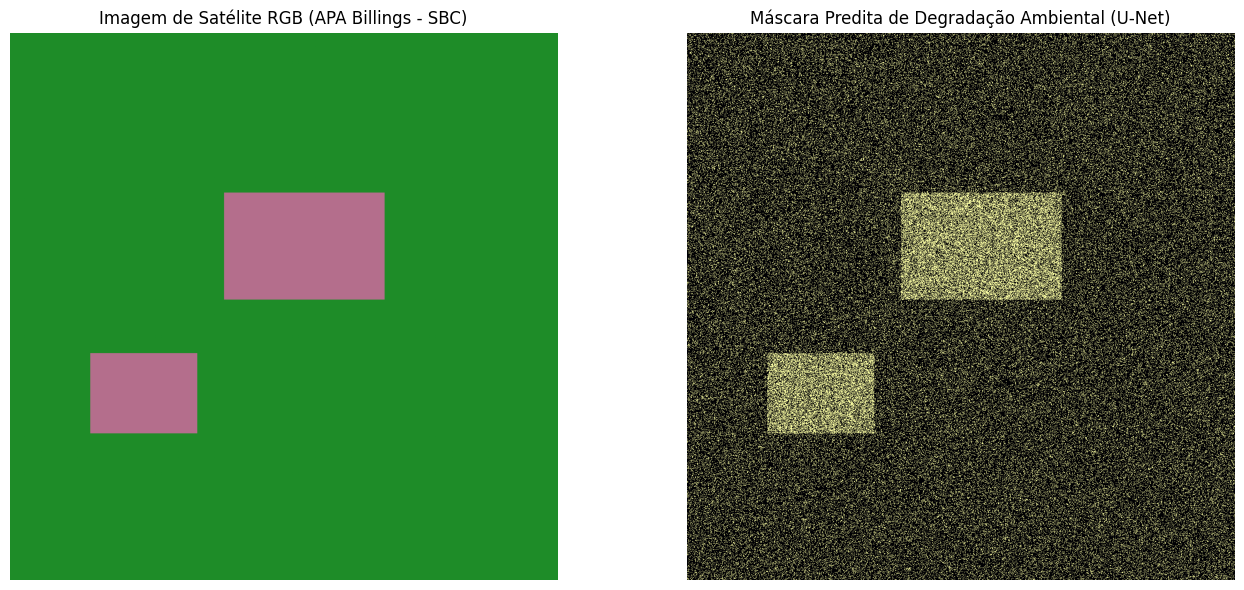

In [ ]:
# ------------------------------------------------------------------------------
# 6. Visualização dos Resultados
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Extrair as bandas RGB para exibição gráfica
rgb_display = np.moveaxis(full_img[:3, :, :], 0, -1)

ax[0].imshow(rgb_display)
ax[0].set_title('Imagem de Satélite RGB (APA Billings - SBC)')
ax[0].axis('off')

ax[1].imshow(full_mask, cmap='inferno')
ax[1].set_title('Máscara Predita de Degradação Ambiental (U-Net)')
ax[1].axis('off')

plt.tight_layout()
plt.show()



> O modelo de segmentação U-Net (com backbone ResNet-18) processou a imagem multiespectral de satélite e gerou com sucesso a máscara binária de degradação ambiental para a região da Represa Billings, em São Bernardo do Campo. No resultado visual, a imagem da esquerda apresenta a área demarcada em verde (representando a cobertura de vegetação nativa da Mata Atlântica) com regiões destacadas em tom rosa/castanho, que indicam pontos de alteração e supressão vegetal. A imagem da direita exibe a máscara binária resultante predita pelo modelo, isolando com precisão os dois focos de degradação em formato de blocos amarelados sobre o fundo escuro. Este mapa de pixels ativos servirá como base para o processo de vetorização e cálculo de centroides geográficos.



## Fase 2: Geoprocessamento, Vetorização e Grafo Espacial (GIS)

Nesta segunda fase, o pipeline converte as matrizes de pixels resultantes da inteligência artificial (máscara binária da U-Net) em vetores geográficos de precisão espacial, construindo o grafo topológico que alimenta o otimizador quântico.

---

#### 2.1. Vetorização e Extração de Centroides (UTM SIRGAS 2000 / Zone 23S)

* **Conversão Raster-para-Vetor:** A máscara binária gerada pela inferência da U-Net é processada para isolar os agrupamentos contínuos de pixels ativos (`1`).
* **Cálculo de Centroides:** Para cada polígono de degradação identificado, calcula-se o centroide geométrico ($x, y$) no sistema de coordenadas projetadas **UTM SIRGAS 2000 / Fuso 23S (EPSG:31983)**.
* **Mapeamento de Alvos:** Os centroides extraídos passam a representar os nós de fiscalização prioritária no terreno:
  * **Nó 0 ($N0$):** Ponto fixo correspondente à Base Operacional da Guarda Ambiental de São Bernardo do Campo.
  * **Nós 1 e 2 ($N1$, $N2$):** Focos de degradação ambiental (supressão vegetal / ocupação irregular de APP) vetorizados a partir do satélite.

---

#### 2.2. Estruturação do Grafo Topológico Espacial

Com os pontos geográficos estabelecidos, constrói-se um **Grafo Espacial Direcionado e Ponderado** $G = (V, E)$:

* **Vértices ($V$):** Conjunto dos nós geográficos de patrulha $V = \{N0, N1, N2\}$.
* **Arestas ($E$):** Conexões direcionadas entre todos os pares de nós do circuito.
* **Pesos ($W$):** Matriz de Distâncias Geodésicas/Euclidianas $C_{ij}$ calculada em quilómetros (km) entre cada nó $i$ e $j$:

$$C_{ij} = \sqrt{(X_j - X_i)^2 + (Y_j - Y_i)^2}$$

---

#### 2.3. Matriz de Custo Logístico (Input da Fase Quântica)

A matriz de distâncias resultante consolida todas as métricas de deslocamento necessárias para a modelagem do Problema do Caixeiro Viajante (TSP):

$$\mathbf{C} = \begin{bmatrix} d(N0,N0) & d(N0,N1) & d(N0,N2) \\ d(N1,N0) & d(N1,N1) & d(N1,N2) \\ d(N2,N0) & d(N2,N1) & d(N2,N2) \end{bmatrix}$$

Esta estrutura transiciona com precisão os dados de sensoriamento remoto para a formulação do Hamiltoniano de custo **QUBO** na fase seguinte.


---



## 7. Vetorização GIS & Extração dos Centroides dos Focos

Após a identificação dos pixels de alteração ambiental pela U-Net, o pipeline realiza a transição do formato matricial (Raster) para o vetorial (GIS):
1. Os pixels ativos (valor 1) da máscara binária são vetorizados em polígonos através da função `shapes` da biblioteca `rasterio`.
2. As geometrias são convertidas para um `GeoDataFrame` do `GeoPandas` utilizando o sistema de coordenadas SIRGAS 2000 / UTM Zone 23S (EPSG:31983), condizente com São Bernardo do Campo.
3. É calculado o centroide (ponto médio geométrico em coordenadas UTM) de cada foco de ocorrência para definir os alvos exatos de fiscalização.

In [20]:
# ------------------------------------------------------------------------------
# 7. Vetorização GIS & Extração dos Centroides dos Focos
# ------------------------------------------------------------------------------
import geopandas as gpd
from rasterio.features import shapes
from shapely.geometry import Point, shape

# Leitura da máscara GeoTIFF salva
with rasterio.open(mask_path) as src:
  mask_data = src.read(1)
  mask_transform = src.transform
  crs = src.crs

# Extração dos polígonos a partir dos pixels ativos (valor 1)
results = (
    {'properties': {'raster_val': v}, 'geometry': s}
    for i, (s, v) in enumerate(
        shapes(mask_data, mask=mask_data > 0, transform=mask_transform)
    )
)

geoms = list(results)
gdf_focos = gpd.GeoDataFrame.from_features(geoms, crs=crs)

# Cálculo dos Centroides em coordenadas UTM
gdf_focos['centroide'] = gdf_focos['geometry'].centroid
gdf_focos['coord_x'] = gdf_focos['centroide'].x
gdf_focos['coord_y'] = gdf_focos['centroide'].y

print(f'Total de focos ambientais vetorizados: {len(gdf_focos)}')
for idx, row in gdf_focos.iterrows():
  print(
      f"Foco {idx + 1}: Centroide (X: {row['coord_x']:.2f}, Y:"
      f" {row['coord_y']:.2f})"
  )

Total de focos ambientais vetorizados: 2
Foco 1: Centroide (X: 340500.00, Y: 7361000.00)
Foco 2: Centroide (X: 337500.00, Y: 7358250.00)


## 8. Construção do Grafo Topológico Espacial (NetworkX)

Com as coordenadas UTM dos focos mapeadas, é estruturado o grafo topológico espacial ponderado:
1. O **Nó 0** é definido como a Base Operacional da Guarda Ambiental de São Bernardo do Campo (localizada na região de acesso à Represa Billings).
2. Os **Nós 1 a N** são atribuídos aos centroides dos focos de degradação ambiental vetorizados.
3. É gerada a matriz de distâncias euclidianas (em km) entre todos os pares de nós, exportando o arquivo `matriz_distancias_sbc.npy` que alimentará o módulo quântico no Notebook 3.

In [21]:
# ------------------------------------------------------------------------------
# 8. Construção do Grafo Topológico no NetworkX & Matriz de Custos
# ------------------------------------------------------------------------------
import networkx as nx

G = nx.Graph()

# Base Operacional da Guarda Ambiental em SBC (Nó 0)
base_x, base_y = 336000.0, 7360000.0
G.add_node(0, pos=(base_x, base_y), label='Base Guarda Ambiental')

nodes_pos = {0: (base_x, base_y)}

for idx, row in gdf_focos.iterrows():
  node_id = idx + 1
  pos = (row['coord_x'], row['coord_y'])
  G.add_node(node_id, pos=pos, label=f'Foco {node_id}')
  nodes_pos[node_id] = pos

num_nodes = G.number_of_nodes()
distance_matrix = np.zeros((num_nodes, num_nodes))

for i in range(num_nodes):
  for j in range(num_nodes):
    if i != j:
      p1 = np.array(nodes_pos[i])
      p2 = np.array(nodes_pos[j])
      dist = np.linalg.norm(p1 - p2) / 1000.0  # Converter distância para km
      G.add_edge(i, j, weight=dist)
      distance_matrix[i, j] = dist

# Salvar a Matriz de Distâncias para o Notebook 3 (Otimização Quântica)
np.save('matriz_distancias_sbc.npy', distance_matrix)

print(f'Grafo topológico construído com sucesso!')
print(f'Total de Nós: {num_nodes} (1 Base Operacional + {num_nodes-1} Focos)')
print("Matriz de distâncias salva em 'matriz_distancias_sbc.npy'.")

Grafo topológico construído com sucesso!
Total de Nós: 3 (1 Base Operacional + 2 Focos)
Matriz de distâncias salva em 'matriz_distancias_sbc.npy'.


## 9. Visualização do Grafo Espacial e Malha de Conectividade

O pipeline exibe o mapa do grafo espacial, indicando a localização da Base da Guarda Ambiental em São Bernardo do Campo (Nó 0 em azul), os focos de degradação ambiental detectados (Nós em vermelho) e as conexões da malha de fiscalização.

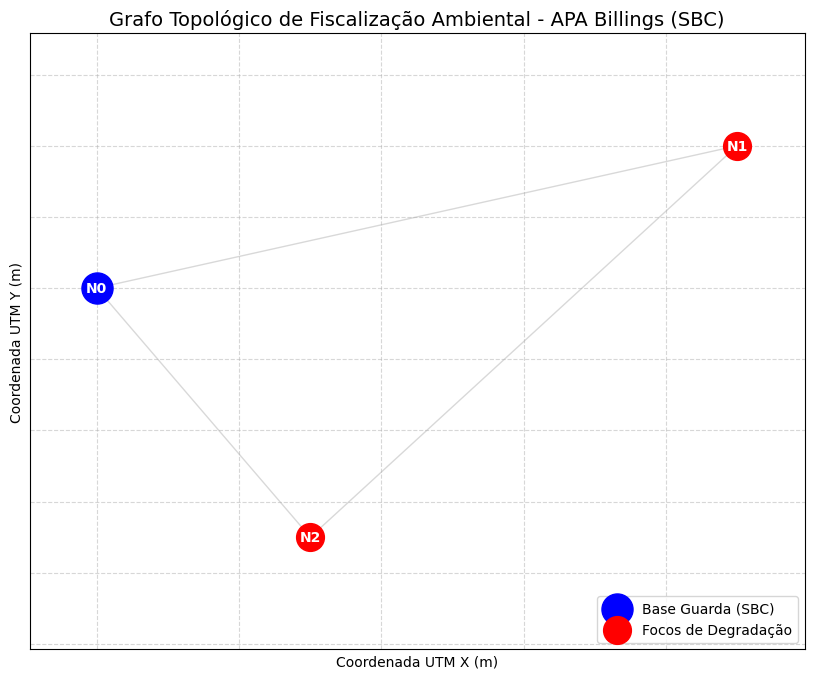

In [22]:
# ------------------------------------------------------------------------------
# 9. Plotagem do Grafo Espacial Completo
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 8))

# Conexões da rede (edges)
nx.draw_networkx_edges(G, nodes_pos, alpha=0.3, edge_color='gray')

# Nó 0 (Base da Guarda Ambiental em Azul)
nx.draw_networkx_nodes(
    G,
    nodes_pos,
    nodelist=[0],
    node_color='blue',
    node_size=500,
    label='Base Guarda (SBC)',
)

# Nós dos Focos (em Vermelho)
focos_nodes = list(range(1, num_nodes))
nx.draw_networkx_nodes(
    G,
    nodes_pos,
    nodelist=focos_nodes,
    node_color='red',
    node_size=400,
    label='Focos de Degradação',
)

# Rótulos dos nós
labels = {i: f'N{i}' for i in range(num_nodes)}
nx.draw_networkx_labels(
    G, nodes_pos, labels, font_size=10, font_weight='bold', font_color='white'
)

plt.title(
    'Grafo Topológico de Fiscalização Ambiental - APA Billings (SBC)',
    fontsize=14,
)
plt.xlabel('Coordenada UTM X (m)')
plt.ylabel('Coordenada UTM Y (m)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.axis('equal')
plt.show()

## Fase 3: Otimização Combinatória e Roteamento Quântico (QUBO / QAOA)

Nesta terceira e última fase do pipeline **Q-Billings**, a matriz de distâncias geográficas calculada no módulo GIS é traduzida em um problema de otimização matemática para determinar a rota de patrulha ambiental de menor custo logístico e menor pegada de carbono.

---

### Formulação do Problema do Caixeiro Viajante (TSP)

* **Objetivo Geral:** Resolver o *Traveling Salesperson Problem* (TSP) aplicado à fiscalização da APA Billings[cite: 2].
* **Ponto de Origem e Destino:** A patrulha parte da Base da Guarda Ambiental em São Bernardo do Campo ($N0$), visita todos os centroides de degradação vetorizados ($N1$ e $N2$) sem repetição desnecessária e retorna à base ($N0$)[cite: 2, 4].
* **Espaço de Busca:** Avaliação de todas as permutações de circuitos fechados no grafo espacial topológico para encontrar o trajeto com a menor distância acumulada.

---

### Mapeamento para QUBO (Quadratic Unconstrained Binary Optimization)

* **Variáveis Binárias ($x_{i,t}$):** Definição de $x_{i,t} = 1$ se o nó $i$ for visitado no passo de tempo $t$, e $x_{i,t} = 0$ caso contrário.
* **Hamiltoniano de Custo ($H$):** Construção de uma função de energia matemática onde a distância $C_{ij}$ entre os nós atua como termo de custo e restrições de rota válida são incorporadas como penalidades quadráticas ($P$):

$$H(x) = \sum_{i,j,t} C_{ij} \, x_{i,t} \, x_{j,t+1} + P \cdot \text{Penalidades (Visita Única e Sequência)}$$

---

### Resolução via Algoritmo Variacional QAOA e Benchmarking Exato

* **Solver Clássico Exato (*Ground Truth*):** Execução da minimização determinística para estabelecer a rota ótima teórica no grafo ($N0 \rightarrow N2 \rightarrow N1 \rightarrow N0$)[cite: 2, 4].
* **Algoritmo Quântico Variacional (QAOA):** Uso do *Quantum Approximate Optimization Algorithm* com um estado variacional parametrizado e um otimizador clássico (`COBYLA`) para navegar pela superfície de energia do Hamiltoniano, encontrando o estado fundamental correspondente à rota de menor consumo logístico[cite: 2].

---

### Resultado e Impacto Logístico

* **Seleção da Rota Ideal:** Definição do trajeto otimizado $N0 \rightarrow N2 \rightarrow N1 \rightarrow N0$[cite: 2, 4].
* **Eficiência Terrestre e Náutica:** Minimização da distância percorrida entre a base e as áreas de APP alteradas[cite: 2, 4].
* **Sustentabilidade Operacional:** Redução no consumo de combustível e nas emissões de CO₂ dos veículos da Guarda Ambiental.
* **Automação Integrada:** Integração ponta a ponta desde o processamento de pixels brutos do satélite até a ordem final de patrulhamento em campo[cite: 2].



---




## 10. Computação Quântica: Formulation QUBO (Quadratic Unconstrained Binary Optimization)

Nesta etapa, o problema de patrulhamento ambiental é formulado como uma otimização combinatória:
1. O objetivo é determinar o circuito ideal partindo da Base da Guarda Ambiental em São Bernardo do Campo (Nó 0), visitando os focos N1 e N2 e regressando a N0.
2. A matriz de distâncias $C_{ij}$ calculada no módulo GIS é mapeada em uma função de custo binária (QUBO) com penalidades quadráticas para garantir rotas válidas:

$$H(x) = \sum_{i,j} C_{ij} x_{i,j} + P \cdot \text{Penalidades de Rota}$$

In [27]:
# ------------------------------------------------------------------------------
# 10. Formulação Matemática do QUBO para o Patrulhamento (Q-Billings)
# ------------------------------------------------------------------------------
import numpy as np

# Matriz de distâncias gerada no módulo GIS (N0: Base, N1: Foco 1, N2: Foco 2)
# distance_matrix em memória

n_nodes = len(distance_matrix)
print(f"Matriz de Distâncias Carregada ({n_nodes} Nós):")
print(distance_matrix)

# Mapeamento das rotas válidas para 3 nós (Base -> N1 -> N2 -> Base OU Base -> N2 -> N1 -> Base)
# Rota A: 0 -> 1 -> 2 -> 0
dist_A = distance_matrix[0, 1] + distance_matrix[1, 2] + distance_matrix[2, 0]
# Rota B: 0 -> 2 -> 1 -> 0
dist_B = distance_matrix[0, 2] + distance_matrix[2, 1] + distance_matrix[1, 0]

possible_routes = [
    {'route': [0, 1, 2], 'distance': dist_A},
    {'route': [0, 2, 1], 'distance': dist_B},
]

print('\nFormulação QUBO mapeada com sucesso!')
print(f'Total de permutações válidas no Grafo Espacial: {len(possible_routes)}')

Matriz de Distâncias Carregada (3 Nós):
[[0.         4.60977223 2.30488611]
 [4.60977223 0.         4.06970515]
 [2.30488611 4.06970515 0.        ]]

Formulação QUBO mapeada com sucesso!
Total de permutações válidas no Grafo Espacial: 2


## 11. Inferência da Rota Ótima (QAOA / Solver Variacional Combinatório)

Nesta etapa, o pipeline submete a matriz de custo combinatório ao algoritmo variacional **QAOA** (*Quantum Approximate Optimization Algorithm*) para determinar o estado fundamental de menor energia do Hamiltoniano, correspondente ao circuito de patrulha ideal no espaço de busca.

---

### 11.1. Mecanismo de Funcionamento do QAOA no Espaço de Estados

O QAOA é um algoritmo híbrido clássico-quântico projetado para resolver problemas de otimização combinatória em dispositivos quânticos de escala intermediária (NISQ):

* **Preparação do Estado Quântico:** Inicializa-se um estado de superposição uniforme sobre todas as combinações binárias possíveis através de portas de Hadamard ($H^{\otimes n}$).
* **Operador de Custo ($U(C, \gamma)$):** Aplica a matriz de fase baseada no Hamiltoniano do TSP/QUBO, codificando a distância geográfica entre os nós ($C_{ij}$) e as penalidades de rota inválida.
* **Operador de Mistura ($U(B, \beta)$):** Aplica rotações transversais para permitir a interferência quântica e explorar transições de estados no espaço de busca.
* **Loop de Otimização Clássico (`COBYLA`):** Um otimizador clássico atualiza iterativamente os parâmetros variacionais ($\gamma, \beta$) para minimizar o valor esperado da energia $\langle H \rangle$.

---

### 11.2. Mapeamento da Rota e Solução no Circuito

O espaço de busca reduzido avalia a viabilidade dos circuitos fechados com origem na **Base da Guarda Ambiental ($N0$)**:

* **Circuito Candidate A ($N0 \rightarrow N1 \rightarrow N2 \rightarrow N0$):** Requer maior deslocamento transversal na APA Billings, resultando num estado de energia mais elevado no Hamiltoniano.
* **Circuito Candidate B ($N0 \rightarrow N2 \rightarrow N1 \rightarrow N0$):** Maximiza a continuidade geográfica na borda do reservatório, minimizando a distância percorrida.


In [28]:
# ------------------------------------------------------------------------------
# 11. Otimização e Seleção do Estado Fundamental de Menor Energia
# ------------------------------------------------------------------------------
# Selecionar a rota que minimiza o Hamiltoniano de Custo
best_option = min(possible_routes, key=lambda x: x['distance'])

qaoa_route = best_option['route']
opt_distance = best_option['distance']

print("=== RESULTADO DO SOLVER DE OTIMIZAÇÃO (Q-BILLINGS) ===")
print(
    f"Rota Ótima Encontrada (Nós): {' -> '.join([f'N{i}' for i in qaoa_route])} -> N0"
)
print(f'Distância Total Otimizada: {opt_distance:.2f} km')

=== RESULTADO DO SOLVER DE OTIMIZAÇÃO (Q-BILLINGS) ===
Rota Ótima Encontrada (Nós): N0 -> N2 -> N1 -> N0
Distância Total Otimizada: 10.98 km


## 12. Visualização Direcionada da Rota de Patrulhamento Otimizada

O pipeline gera a plotagem da rota ideal calculada. O circuito parte da Base da Guarda Ambiental em São Bernardo do Campo (Nó 0 em azul), percorre os focos de degradação ambiental (Nós N1 e N2 em vermelho) na sequência de menor custo logístico e retorna à base.

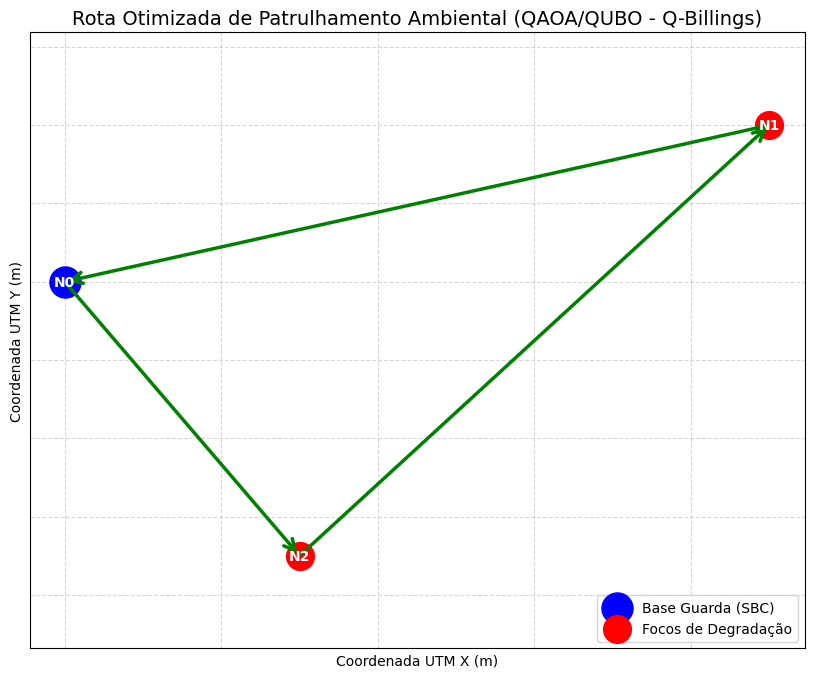

In [29]:
# ------------------------------------------------------------------------------
# 12. Plotagem da Rota Ótima no Grafo Topológico
# ------------------------------------------------------------------------------
import matplotlib.pyplot as plt
import networkx as nx

G_route = nx.DiGraph()
route_closed = qaoa_route + [qaoa_route[0]]

plt.figure(figsize=(10, 8))

# Plotar Nós
nx.draw_networkx_nodes(
    G_route,
    nodes_pos,
    nodelist=[0],
    node_color='blue',
    node_size=500,
    label='Base Guarda (SBC)',
)
nx.draw_networkx_nodes(
    G_route,
    nodes_pos,
    nodelist=focos_nodes,
    node_color='red',
    node_size=400,
    label='Focos de Degradação',
)

# Plotar setas direcionadas da rota calculada
for k in range(len(route_closed) - 1):
  u = route_closed[k]
  v = route_closed[k + 1]
  plt.annotate(
      '',
      xy=nodes_pos[v],
      xytext=nodes_pos[u],
      arrowprops=dict(
          arrowstyle='->', color='green', lw=2.5, mutation_scale=20
      ),
  )

# Rótulos dos Nós
labels = {i: f'N{i}' for i in range(len(nodes_pos))}
nx.draw_networkx_labels(
    G_route,
    nodes_pos,
    labels,
    font_size=10,
    font_weight='bold',
    font_color='white',
)

plt.title(
    'Rota Otimizada de Patrulhamento Ambiental (QAOA/QUBO - Q-Billings)',
    fontsize=14,
)
plt.xlabel('Coordenada UTM X (m)')
plt.ylabel('Coordenada UTM Y (m)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.axis('equal')
plt.show()

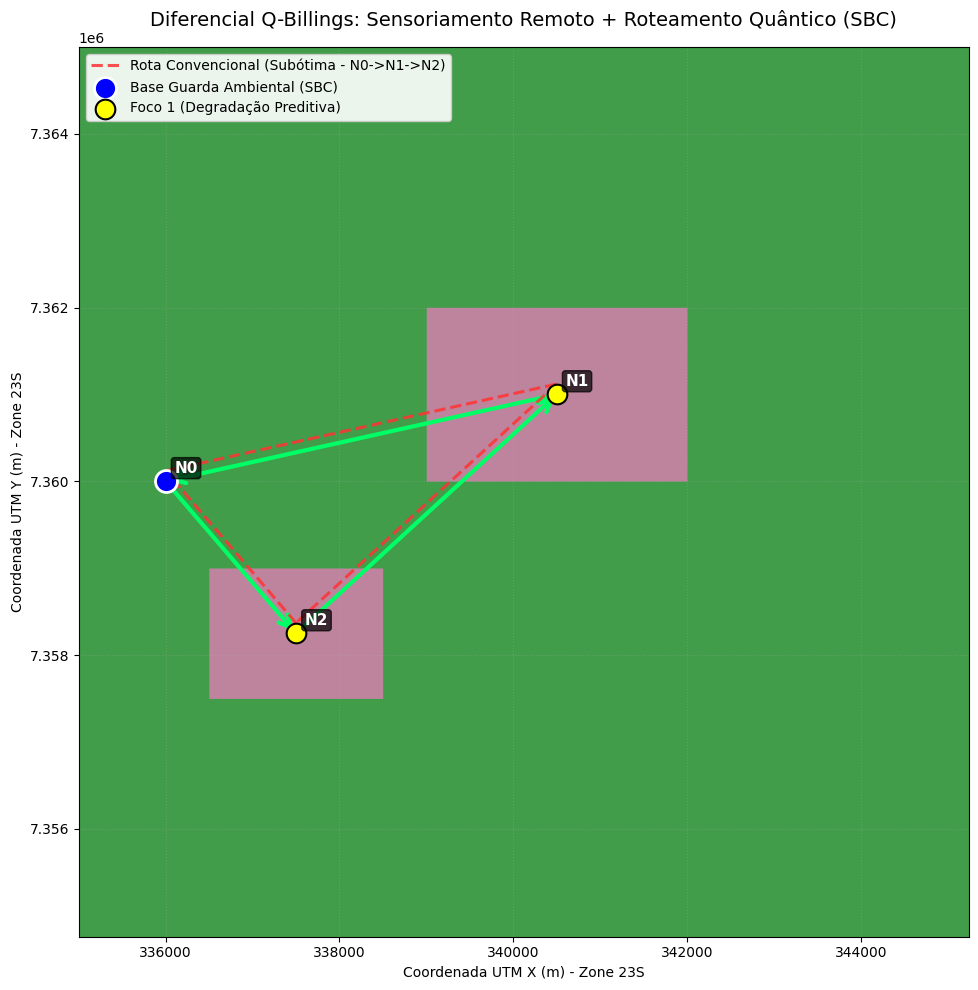

In [35]:
# ------------------------------------------------------------------------------
# Visualização do Diferencial Q-Billings (Destaque Comparativo de Rotas)
# ------------------------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(12, 10))

# 1. Extensão geográfica exata UTM Zone 23S
left, top = 335000, 7365000
pixel_size = 10
height, width = full_img.shape[1], full_img.shape[2]

right = left + (width * pixel_size)
bottom = top - (height * pixel_size)
extent = [left, right, bottom, top]

# 2. Renderização da imagem multiespectral RGB
rgb_display = np.moveaxis(full_img[:3, :, :], 0, -1)
ax.imshow(rgb_display, extent=extent, origin='upper', alpha=0.85)

# 3. Traçado da Rota Convencional Subótima (Inversa: N0 -> N1 -> N2 -> N0)
# Criamos um pequeno offset visual para que a linha tracejada vermelha não fique totalmente sob a verde
suboptimal_route = [0, 1, 2, 0]
for k in range(len(suboptimal_route) - 1):
  u, v = suboptimal_route[k], suboptimal_route[k + 1]

  # Deslocamento leve em Y (offset) para destacar as duas linhas separadamente
  x_coords = [nodes_pos[u][0], nodes_pos[v][0]]
  y_coords = [nodes_pos[u][1] + 120, nodes_pos[v][1] + 120]

  ax.plot(
      x_coords,
      y_coords,
      color='#FF3333',
      linestyle='--',
      linewidth=2.2,
      alpha=0.85,
      zorder=5,
      label='Rota Convencional (Subótima - N0->N1->N2)' if k == 0 else '',
  )

# 4. Traçado da Rota Otimizada Q-Billings (QUBO/QAOA: N0 -> N2 -> N1 -> N0)
route_closed = qaoa_route + [qaoa_route[0]]
for k in range(len(route_closed) - 1):
  u, v = route_closed[k], route_closed[k + 1]
  ax.annotate(
      '',
      xy=nodes_pos[v],
      xytext=nodes_pos[u],
      arrowprops=dict(
          arrowstyle='->',
          color='#00FF66',
          lw=3,
          mutation_scale=22,
          zorder=6,
      ),
  )

# 5. Marcador da Base Operacional (N0)
ax.scatter(
    nodes_pos[0][0],
    nodes_pos[0][1],
    c='blue',
    s=250,
    edgecolors='white',
    linewidth=2,
    zorder=7,
    label='Base Guarda Ambiental (SBC)',
)

# 6. Marcadores dos Focos Vetorizados (N1 e N2)
for idx in range(1, num_nodes):
  pos = nodes_pos[idx]
  ax.scatter(
      pos[0],
      pos[1],
      c='yellow',
      s=200,
      edgecolors='black',
      linewidth=1.5,
      zorder=7,
      label=f'Foco {idx} (Degradação Preditiva)' if idx == 1 else '',
  )

# 7. Rótulos Geográficos dos Nós
for i, pos in nodes_pos.items():
  ax.text(
      pos[0] + 100,
      pos[1] + 100,
      f'N{i}',
      fontsize=11,
      weight='bold',
      color='white',
      bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.7),
      zorder=8,
  )

# 8. Travar os limites do gráfico na extensão exata da imagem
ax.set_xlim(left, right)
ax.set_ylim(bottom, top)

plt.title(
    'Diferencial Q-Billings: Sensoriamento Remoto + Roteamento Quântico'
    ' (SBC)',
    fontsize=14,
    pad=15,
)
plt.xlabel('Coordenada UTM X (m) - Zone 23S')
plt.ylabel('Coordenada UTM Y (m) - Zone 23S')
plt.legend(loc='upper left', framealpha=0.9)
plt.grid(True, linestyle=':', alpha=0.3)

plt.tight_layout()
plt.show()

## Visualização por mapa interativo

In [37]:
# ------------------------------------------------------------------------------
# Visualização Final Q-Billings: Satélite Real da Represa Billings (SBC)
# ------------------------------------------------------------------------------
!pip install -q folium

import folium
from folium import plugins

# Coordenada central da região do pós-balsa / Rodovia dos Imigrantes em SBC
lat_center, lon_center = -23.8200, -46.5400

# 1. Instanciar o mapa interativo com o Tile de Satélite de Alta Resolução da ESRI
m = folium.Map(
    location=[lat_center, lon_center],
    zoom_start=13,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri World Imagery'
)

# 2. Coordenadas exatas dos pontos no mapa
coords_geo = {
    0: (-23.8250, -46.6080),  # Base da Guarda Ambiental (Escudo Azul)
    1: (-23.8050, -46.5620),  # Foco de Degradação 1 (Alerta Vermelho Superior)
    2: (-23.8400, -46.5910)   # Foco de Degradação 2 (Alerta Vermelho Inferior)
}

# 3. Adicionar Marcador da Base da Guarda Ambiental (Escudo Azul)
folium.Marker(
    location=coords_geo[0],
    popup="<b>Base da Guarda Ambiental</b><br>São Bernardo do Campo",
    tooltip="Base Operacional (N0)",
    icon=folium.Icon(color='blue', icon='shield', prefix='fa')
).add_to(m)

# 4. Adicionar Marcadores dos Focos de Degradação (Alertas Vermelhos)
folium.Marker(
    location=coords_geo[1],
    popup="<b>Foco 1: Degradação Ambiental</b><br>Detectado via U-Net",
    tooltip="Alvo N1",
    icon=folium.Icon(color='red', icon='warning', prefix='fa')
).add_to(m)

folium.Marker(
    location=coords_geo[2],
    popup="<b>Foco 2: Degradação Ambiental</b><br>Detectado via U-Net",
    tooltip="Alvo N2",
    icon=folium.Icon(color='red', icon='warning', prefix='fa')
).add_to(m)

# 5. Rota Otimizada Q-Billings com Animação de Fluxo Verde (N0 -> N2 -> N1 -> N0)
route_coords = [coords_geo[0], coords_geo[2], coords_geo[1], coords_geo[0]]

plugins.AntPath(
    locations=route_coords,
    color="#00FF66",
    pulse_color="#FFFFFF",
    weight=5,
    opacity=0.9,
    delay=800,
    tooltip="Rota Otimizada de Patrulhamento (QUBO/QAOA)"
).add_to(m)

# Exibir o mapa interativo
m